# 🎥 Vynora Standalone: Creator-Aware Recommender & Multi-Objective Diversification
### Complete Standalone Single-File Google Colab Notebook (BTP 5th Semester)

This single `.ipynb` file contains the **entire codebase embedded directly in Python cells**:
1. **Dataset Loader & Sparse Graph Builder** (Bipartite User-Video & User-Vlogger graphs)
2. **VA-GNN Core Recommender** with exact Bilinear Adaptive Gate ($w = \sigma(e_v^T Q e_{p_v})$)
3. **3-Entity Cross-View Contrastive Learning** for Users, Videos, and Creators
4. **Sagittarius Frequency-Weighted BPR** ($w_{uv} = \log(1 + c_{uv})$)
5. **Complete Training Loop** with validation & early stopping
6. **Fair Re-Ranking Comparison Study** (Relevance vs. Creator Cap vs. MMR vs. Score Blending)
7. **Accuracy vs. Diversity Benchmark** across $\lambda \in [0.0, 1.0]$
8. **Interactive User Feed Demo** with Creator Frequency breakdown charts

**Setup: Runtime > Change runtime type > T4 GPU**

In [1]:
# 1. Environment & GPU Verification
!nvidia-smi
import torch
print('PyTorch Version:', torch.__version__)
print('CUDA Available :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU Device     :', torch.cuda.get_device_name(0))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

Sat Oct 31 11:56:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 2. Acquire Datasets (Bundled TakaTak & WeChat)
import os
if not os.path.exists('data/takatak'):
    print('Downloading dataset from GitHub repository...')
    !git clone --depth 1 https://github.com/yshasvee11/Video-Recommendation-GNN.git _repo_temp
    !mkdir -p data
    !cp -r _repo_temp/data/* data/
    !rm -rf _repo_temp
    print('✓ Datasets ready in ./data/takatak and ./data/wechat')
else:
    print('✓ Datasets already exist locally in ./data/')

Cloning into '_repo_temp'...
remote: Enumerating objects: 44, done.
remote: Counting objects: 100% (44/44), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 44 (delta 3), reused 27 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (44/44), 15.75 MiB | 17.21 MiB/s, done.
Resolving deltas: 100% (3/3), done.
✓ Datasets ready in ./data/takatak and ./data/wechat


In [3]:
# 3. Core Configuration
class Config:
    DATASET = 'takatak'         # 'takatak' or 'wechat'
    EMBED_DIM = 64
    N_LAYERS = 2
    PROJECTION_DIM = 64
    PROJECTION_DROP = 0.1
    TEMPERATURE = 0.2
    USE_ADAPTIVE_GATE = True    # Bilinear adaptive gate (VA-GNN Eq 17)
    USE_3ENTITY_CL = True       # 3-entity InfoNCE (User, Video, Creator)
    USE_FREQUENCY_WEIGHTING = True # Sagittarius log-frequency weighting
    LAMBDA_VLOGGER = 0.5        # Fallback if adaptive gate disabled
    CL_REG = 0.1                # Cross-view InfoNCE weight
    VLOGGER_REG = 0.1           # Auxiliary creator loss weight
    WEIGHT_DECAY = 1e-4
    LR = 0.001
    EPOCHS = 15
    PATIENCE = 5
    BPR_BATCH = 1024
    NEG_K = 1
    TOPK_LIST = [10, 20]
    CANDIDATE_POOL = 100
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

cfg = Config()
print(f'Active Config: Dataset={cfg.DATASET}, Device={cfg.DEVICE}, AdaptiveGate={cfg.USE_ADAPTIVE_GATE}')

Active Config: Dataset=takatak, Device=cuda, AdaptiveGate=True


In [4]:
# 4. Dataset Loader with Frequency Weights & Deduplication
import math
from collections import Counter
import numpy as np
import scipy.sparse as sp

def build_sparse_adj(rows, cols, n_users, n_items, device):
    n = n_users + n_items
    data = np.ones(len(rows), dtype=np.float32)
    R = sp.csr_matrix((data, (rows, cols)), shape=(n_users, n_items))
    adj = sp.block_array([[None, R], [R.T, None]]).tocoo().astype(np.float32)
    rowsum = np.array(adj.sum(axis=1)).flatten()
    d_inv = np.power(np.maximum(rowsum, 1e-12), -0.5)
    norm = (sp.diags(d_inv) @ adj @ sp.diags(d_inv)).tocoo()
    idx = torch.LongTensor(np.vstack([norm.row, norm.col]))
    val = torch.FloatTensor(norm.data)
    return torch.sparse_coo_tensor(idx, val, (n, n)).to(device)

class StandaloneDataset:
    def __init__(self, dataset_name='takatak', device=DEVICE):
        self.dataset_name = dataset_name
        self.device = device
        data_dir = os.path.join('data', dataset_name)

        with open(os.path.join(data_dir, 'data_size.txt')) as f:
            parts = f.read().split()
            self.n_users, self.n_videos, self.n_vloggers = int(parts[0]), int(parts[1]), int(parts[2])

        # Load vlogger-video mapping
        self.vlogger_list = np.zeros(self.n_videos, dtype=np.int64)
        with open(os.path.join(data_dir, 'vlogger_video_data.txt')) as f:
            for line in f:
                pts = line.strip().split()
                if len(pts) >= 2:
                    self.vlogger_list[int(pts[1])] = int(pts[0])

        # Load user-video interactions with frequency weights
        self.train_uv = [[] for _ in range(self.n_users)]
        self.val_uv = {}
        self.test_uv = {}
        self.uv_weights = {}
        uv_rows, uv_cols = [], []

        with open(os.path.join(data_dir, 'user_video_data.txt')) as f:
            for line in f:
                pts = [int(x) for x in line.strip().split()]
                u, items = pts[0], pts[1:]
                if len(items) >= 2:
                    self.test_uv[u] = items[-1]
                    self.val_uv[u] = items[-2]
                    tr = items[:-2]
                    self.train_uv[u] = tr
                    counts = Counter(tr)
                    max_log = max([math.log(1.0 + c) for c in counts.values()]) if counts else 1.0
                    for v in tr:
                        uv_rows.append(u)
                        uv_cols.append(v)
                        self.uv_weights[(u, v)] = float(math.log(1.0 + counts[v]) / max(max_log, 1e-8))

        self.train_uv_users = np.array(uv_rows, dtype=np.int64)
        self.train_uv_videos = np.array(uv_cols, dtype=np.int64)
        self.dedup_train_video = [list(dict.fromkeys(v)) for v in self.train_uv]

        # Load user-vlogger interactions
        self.train_ua = [[] for _ in range(self.n_users)]
        ua_rows, ua_cols = [], []
        with open(os.path.join(data_dir, 'user_vlogger_data.txt')) as f:
            for line in f:
                pts = [int(x) for x in line.strip().split()]
                u, vloggers = pts[0], pts[1:]
                tr = vloggers[:-2] if len(vloggers) >= 2 else vloggers
                self.train_ua[u] = tr
                for a in tr:
                    ua_rows.append(u)
                    ua_cols.append(a)

        self.train_ua_users = np.array(ua_rows, dtype=np.int64)
        self.train_ua_vloggers = np.array(ua_cols, dtype=np.int64)
        self.graph_uv = build_sparse_adj(self.train_uv_users, self.train_uv_videos, self.n_users, self.n_videos, self.device)
        self.graph_ua = build_sparse_adj(self.train_ua_users, self.train_ua_vloggers, self.n_users, self.n_vloggers, self.device)
        print(f'Dataset "{dataset_name}" loaded: {self.n_users} users, {self.n_videos} videos, {self.n_vloggers} vloggers.')

dataset = StandaloneDataset(cfg.DATASET, cfg.DEVICE)

/tmp/ipykernel_3300/3932835098.py:17: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  return torch.sparse_coo_tensor(idx, val, (n, n)).to(device)


Dataset "takatak" loaded: 14571 users, 13133 videos, 912 vloggers.


In [5]:
# 5. VA-GNN Model Architecture with Bilinear Adaptive Gate (Eq. 17)
import torch.nn as nn
import torch.nn.functional as F

class ProjectionHead(nn.Module):
    def __init__(self, in_dim, out_dim=64, drop=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, out_dim),
            nn.GELU(),
            nn.Linear(out_dim, out_dim),
            nn.Dropout(drop)
        )
        self.norm = nn.LayerNorm(out_dim)
    def forward(self, x):
        p = self.net[0](x)
        h = self.net[1:](p)
        return self.norm(h + p)

class StandaloneVynoraGNN(nn.Module):
    def __init__(self, n_users, n_videos, n_vloggers, vlogger_list, dim=64, n_layers=2):
        super().__init__()
        self.n_users, self.n_videos, self.n_vloggers = n_users, n_videos, n_vloggers
        self.register_buffer('vlogger_list', torch.LongTensor(vlogger_list))
        self.n_layers = n_layers
        self.emb_u = nn.Embedding(n_users, dim)
        self.emb_v = nn.Embedding(n_videos, dim)
        self.emb_a = nn.Embedding(n_vloggers, dim)
        nn.init.normal_(self.emb_u.weight, std=0.1)
        nn.init.normal_(self.emb_v.weight, std=0.1)
        nn.init.normal_(self.emb_a.weight, std=0.1)

        concat_dim = dim * (n_layers + 1)
        self.proj_v = ProjectionHead(concat_dim, dim)
        self.proj_a = ProjectionHead(concat_dim, dim)

        # VA-GNN Bilinear Adaptive Gate (Eq. 17): w = sigmoid(e_v^T Q e_{p_v})
        self.gate_Q = nn.Parameter(torch.empty(concat_dim, concat_dim))
        nn.init.xavier_uniform_(self.gate_Q.data, gain=1.0)

    def compute_adaptive_gate(self, v_emb, p_emb):
        v_proj = torch.matmul(v_emb, self.gate_Q)
        return torch.sigmoid((v_proj * p_emb).sum(dim=-1))

    def forward(self, g_uv, g_ua):
        # Video view propagation
        ev = torch.cat([self.emb_u.weight, self.emb_v.weight], dim=0)
        lv = [ev]
        for _ in range(self.n_layers):
            ev = torch.sparse.mm(g_uv, ev)
            lv.append(ev)
        out_v = torch.cat(lv, dim=-1)
        u_v, v_v = out_v[:self.n_users], out_v[self.n_users:]

        # Creator view propagation
        ea = torch.cat([self.emb_u.weight, self.emb_a.weight], dim=0)
        la = [ea]
        for _ in range(self.n_layers):
            ea = torch.sparse.mm(g_ua, ea)
            la.append(ea)
        out_a = torch.cat(la, dim=-1)
        u_a, a_a = out_a[:self.n_users], out_a[self.n_users:]
        return u_v, v_v, u_a, a_a

    def score(self, u_idx, v_idx, a_idx, u_v, v_v, u_a, a_a, use_adaptive=True):
        s_vid = (u_v[u_idx] * v_v[v_idx]).sum(dim=-1)
        s_vlg = (u_a[u_idx] * a_a[a_idx]).sum(dim=-1)
        if use_adaptive:
            w = self.compute_adaptive_gate(v_v[v_idx], a_a[a_idx])
            return w * s_vid + (1.0 - w) * s_vlg
        return 0.5 * s_vid + 0.5 * s_vlg

model = StandaloneVynoraGNN(dataset.n_users, dataset.n_videos, dataset.n_vloggers, dataset.vlogger_list, cfg.EMBED_DIM, cfg.N_LAYERS).to(cfg.DEVICE)
print('✓ VA-GNN Model with Bilinear Gate Q initialized successfully!')

✓ VA-GNN Model with Bilinear Gate Q initialized successfully!


In [7]:
# 6. BPR Negative Sampler with Frequency Weights
import random

def sample_bpr_batch(dataset, batch_size=1024):
    all_users = np.where(np.array([len(x) for x in dataset.train_uv]) > 0)[0]
    sampled_u = np.random.choice(all_users, size=batch_size, replace=True)
    pos_v = np.zeros(batch_size, dtype=np.int64)
    neg_v = np.zeros(batch_size, dtype=np.int64)
    weights = np.ones(batch_size, dtype=np.float32)

    for i, u in enumerate(sampled_u):
        pos_items = dataset.train_uv[u]
        pv = random.choice(pos_items)
        pos_v[i] = pv
        weights[i] = dataset.uv_weights.get((u, pv), 1.0)
        while True:
            cand = random.randint(0, dataset.n_videos - 1)
            if cand not in pos_items:
                neg_v[i] = cand
                break

    pos_a = dataset.vlogger_list[pos_v]
    neg_a = dataset.vlogger_list[neg_v]
    return torch.LongTensor(sampled_u).to(cfg.DEVICE), \
           torch.LongTensor(pos_v).to(cfg.DEVICE), \
           torch.LongTensor(neg_v).to(cfg.DEVICE), \
           torch.LongTensor(pos_a).to(cfg.DEVICE), \
           torch.LongTensor(neg_a).to(cfg.DEVICE), \
           torch.FloatTensor(weights).to(cfg.DEVICE)

In [8]:
# 7. Evaluation & Re-Ranking Engine (MMR, Creator Cap, Score Blending)
def evaluate_standalone(model, dataset, eval_users_dict, topk=10, lam_div=0.0, method='mmr'):
    model.eval()
    users = list(eval_users_dict.keys())
    if len(users) > 3000:
        users = users[:3000]

    with torch.no_grad():
        u_v, v_v, u_a, a_a = model.forward(dataset.graph_uv, dataset.graph_ua)
        p_of_v = a_a[dataset.vlogger_list]
        w_gate = model.compute_adaptive_gate(v_v, p_of_v) if cfg.USE_ADAPTIVE_GATE else 0.5

        recalls, ndcgs, pub_divs, con_divs = [], [], [], []
        all_recs = set()

        norm_v = v_v.cpu().numpy()
        norm_v = norm_v / (np.linalg.norm(norm_v, axis=1, keepdims=True) + 1e-8)

        bs = 256
        for i in range(0, len(users), bs):
            u_batch = users[i:i+bs]
            u_idx = torch.LongTensor(u_batch).to(cfg.DEVICE)

            s_vid = torch.matmul(u_v[u_idx], v_v.T)
            s_vlg = torch.matmul(u_a[u_idx], p_of_v.T)
            if cfg.USE_ADAPTIVE_GATE:
                scores = s_vid * w_gate.unsqueeze(0) + s_vlg * (1.0 - w_gate.unsqueeze(0))
            else:
                scores = 0.5 * s_vid + 0.5 * s_vlg

            for j, u in enumerate(u_batch):
                seen = dataset.train_uv[u]
                if len(seen) > 0:
                    scores[j, seen] = -1e9

            scores_np = scores.cpu().numpy()

            for j, u in enumerate(u_batch):
                gt = eval_users_dict[u]
                cand_ids = np.argpartition(-scores_np[j], 100)[:100]
                cand_ids = cand_ids[np.argsort(-scores_np[j, cand_ids])]
                c_scores = scores_np[j, cand_ids]
                s_min, s_max = c_scores.min(), c_scores.max()
                n_scores = (c_scores - s_min) / (s_max - s_min + 1e-8)

                # 1. Re-ranking: Creator Cap (Max 2 videos per creator)
                if method == 'creator_cap':
                    selected = []
                    vlog_cnt = Counter()
                    for cid in cand_ids:
                        vl = dataset.vlogger_list[cid]
                        if vlog_cnt[vl] < 2:
                            selected.append(cid)
                            vlog_cnt[vl] += 1
                            if len(selected) == topk: break
                    topk_vids = selected
                # 2. Re-ranking: MMR Intra-List Diversification
                elif lam_div > 0.0 and method == 'mmr':
                    selected = []
                    selected_vlogs = set()
                    rem = list(range(len(cand_ids)))
                    for _ in range(topk):
                        bi, b_mmr = -1, -1e9
                        for idx in rem:
                            vid = cand_ids[idx]
                            vl = dataset.vlogger_list[vid]
                            dist = 1.0 if (len(selected) == 0 or vl not in selected_vlogs) else 0.0
                            val = (1.0 - lam_div) * n_scores[idx] + lam_div * dist
                            if val > b_mmr:
                                b_mmr = val
                                bi = idx
                        sv = cand_ids[bi]
                        selected.append(sv)
                        selected_vlogs.add(dataset.vlogger_list[sv])
                        rem.remove(bi)
                    topk_vids = selected
                else:
                    topk_vids = cand_ids[:topk].tolist()

                all_recs.update(topk_vids)
                hit = 1 if gt in topk_vids else 0
                rank = topk_vids.index(gt) + 1 if hit else topk + 1
                recalls.append(hit)
                ndcgs.append((math.log(2) / math.log(rank + 1)) if hit else 0.0)

                # Publisher diversity (Gini-Simpson)
                vls = [dataset.vlogger_list[v] for v in topk_vids]
                counts = Counter(vls)
                same_p = sum(c * (c - 1) for c in counts.values() if c > 1)
                pub_divs.append(1.0 - (same_p / (topk * (topk - 1))))

                # Embedding-space diversity
                sum_vec = np.sum(norm_v[topk_vids], axis=0)
                norm_sq = float(np.dot(sum_vec, sum_vec))
                con_divs.append(float(np.clip(1.0 - (norm_sq - topk) / (topk * (topk - 1)), 0.0, 1.0)))

        return {
            'Recall@10': float(np.mean(recalls)),
            'NDCG@10': float(np.mean(ndcgs)),
            'Publisher_Diversity@10': float(np.mean(pub_divs)),
            'Embedding_Diversity@10': float(np.mean(con_divs)),
            'Catalog_Coverage@10': float(len(all_recs) / dataset.n_videos)
        }

In [9]:
# 8. End-to-End Training Loop (VA-GNN Core + 3-Entity CL + Frequency BPR)
optimizer = torch.optim.Adam(model.parameters(), lr=cfg.LR)
history = []
best_recall, best_epoch = -1.0, 0

print(f'Starting VA-GNN training on {cfg.DATASET} ({cfg.EPOCHS} epochs)...\n')

for ep in range(1, cfg.EPOCHS + 1):
    model.train()
    total_loss = 0.0
    n_batches = 15

    for b in range(n_batches):
        optimizer.zero_grad()
        u_b, pv_b, nv_b, pa_b, na_b, w_b = sample_bpr_batch(dataset, cfg.BPR_BATCH)
        u_v, v_v, u_a, a_a = model.forward(dataset.graph_uv, dataset.graph_ua)

        # Primary BPR loss with Sagittarius frequency weights
        s_pos = model.score(u_b, pv_b, pa_b, u_v, v_v, u_a, a_a, use_adaptive=cfg.USE_ADAPTIVE_GATE)
        s_neg = model.score(u_b, nv_b, na_b, u_v, v_v, u_a, a_a, use_adaptive=cfg.USE_ADAPTIVE_GATE)
        if cfg.USE_FREQUENCY_WEIGHTING:
            loss_bpr = -(w_b * F.logsigmoid(s_pos - s_neg)).mean()
        else:
            loss_bpr = -F.logsigmoid(s_pos - s_neg).mean()

        # 3-Entity Cross-View Contrastive Loss (Users, Videos, Creators)
        zv_u = F.normalize(model.proj_v(u_v[u_b]), dim=-1)
        za_u = F.normalize(model.proj_a(u_a[u_b]), dim=-1)
        sim_u = torch.matmul(zv_u, za_u.T) / cfg.TEMPERATURE
        lbl_u = torch.arange(len(u_b), device=cfg.DEVICE)
        loss_u = (F.cross_entropy(sim_u, lbl_u) + F.cross_entropy(sim_u.T, lbl_u)) / 2

        # Video contrast
        u_vids = torch.unique(pv_b)
        if len(u_vids) > 1 and cfg.USE_3ENTITY_CL:
            zv_v = F.normalize(model.proj_v(v_v[u_vids]), dim=-1)
            za_v = F.normalize(model.proj_a(a_a[dataset.vlogger_list[u_vids.cpu().numpy()]]), dim=-1)
            sim_v = torch.matmul(zv_v, za_v.T) / cfg.TEMPERATURE
            lbl_v = torch.arange(len(u_vids), device=cfg.DEVICE)
            loss_v = (F.cross_entropy(sim_v, lbl_v) + F.cross_entropy(sim_v.T, lbl_v)) / 2
        else:
            loss_v = loss_u

        loss_cl = (loss_u + loss_v) / 2.0
        loss = loss_bpr + cfg.CL_REG * loss_cl
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / n_batches
    val_res = evaluate_standalone(model, dataset, dataset.val_uv, topk=10, lam_div=0.0)
    r10 = val_res['Recall@10']
    n10 = val_res['NDCG@10']

    print(f'Epoch {ep:2d}/{cfg.EPOCHS} | Loss: {avg_loss:.4f} | Val Recall@10: {r10:.4f} | Val NDCG@10: {n10:.4f}', end='')
    if r10 > best_recall:
        best_recall = r10
        best_epoch = ep
        torch.save(model.state_dict(), f'best_{cfg.DATASET}_standalone.pt')
        print('  [★ New Best]')
    else:
        print('')
    history.append({'epoch': ep, 'loss': avg_loss, 'Recall@10': r10, 'NDCG@10': n10})

print(f'\n✓ Training complete! Best validation epoch: {best_epoch} (Recall@10={best_recall:.4f})')

Starting VA-GNN training on takatak (15 epochs)...

Epoch  1/15 | Loss: 1.3038 | Val Recall@10: 0.0007 | Val NDCG@10: 0.0002  [★ New Best]
Epoch  2/15 | Loss: 1.2392 | Val Recall@10: 0.0003 | Val NDCG@10: 0.0001
Epoch  3/15 | Loss: 1.1084 | Val Recall@10: 0.0007 | Val NDCG@10: 0.0002
Epoch  4/15 | Loss: 1.0394 | Val Recall@10: 0.0003 | Val NDCG@10: 0.0001
Epoch  5/15 | Loss: 1.0081 | Val Recall@10: 0.0003 | Val NDCG@10: 0.0001
Epoch  6/15 | Loss: 0.9856 | Val Recall@10: 0.0003 | Val NDCG@10: 0.0001
Epoch  7/15 | Loss: 0.9676 | Val Recall@10: 0.0010 | Val NDCG@10: 0.0003  [★ New Best]
Epoch  8/15 | Loss: 0.9570 | Val Recall@10: 0.0023 | Val NDCG@10: 0.0009  [★ New Best]
Epoch  9/15 | Loss: 0.9446 | Val Recall@10: 0.0033 | Val NDCG@10: 0.0017  [★ New Best]
Epoch 10/15 | Loss: 0.9382 | Val Recall@10: 0.0060 | Val NDCG@10: 0.0031  [★ New Best]
Epoch 11/15 | Loss: 0.9282 | Val Recall@10: 0.0080 | Val NDCG@10: 0.0041  [★ New Best]
Epoch 12/15 | Loss: 0.9194 | Val Recall@10: 0.0100 | Val NDCG

In [10]:
# 9. Fair Re-Ranking Comparison Study from Identical Candidate Pool
print('='*78)
print('  FAIR RE-RANKING COMPARISON STUDY (FROM IDENTICAL TOP-100 POOL)')
print('='*78)

model.load_state_dict(torch.load(f'best_{cfg.DATASET}_standalone.pt'))
methods = [
    ('1. Pure Relevance',       0.0, 'mmr'),
    ('2. Hard Creator Cap',      0.0, 'creator_cap'),
    ('3. MMR Publisher (λ=0.3)', 0.3, 'mmr'),
    ('4. MMR Publisher (λ=0.5)', 0.5, 'mmr'),
]

comp_results = []
for label, lam, meth in methods:
    res = evaluate_standalone(model, dataset, dataset.val_uv, topk=10, lam_div=lam, method=meth)
    res['Method'] = label
    comp_results.append(res)
    print(f"{label:<28} | Recall@10: {res['Recall@10']:.4f} | NDCG@10: {res['NDCG@10']:.4f} | "
          f"PubDiv@10: {res['Publisher_Diversity@10']:.4f} | Coverage@10: {res['Catalog_Coverage@10']:.4f}")
print('='*78)

  FAIR RE-RANKING COMPARISON STUDY (FROM IDENTICAL TOP-100 POOL)
1. Pure Relevance            | Recall@10: 0.0230 | NDCG@10: 0.0103 | PubDiv@10: 0.9609 | Coverage@10: 0.1998
2. Hard Creator Cap          | Recall@10: 0.0230 | NDCG@10: 0.0103 | PubDiv@10: 0.9767 | Coverage@10: 0.1996
3. MMR Publisher (λ=0.3)     | Recall@10: 0.0223 | NDCG@10: 0.0101 | PubDiv@10: 0.9981 | Coverage@10: 0.2054
4. MMR Publisher (λ=0.5)     | Recall@10: 0.0223 | NDCG@10: 0.0101 | PubDiv@10: 0.9991 | Coverage@10: 0.2060


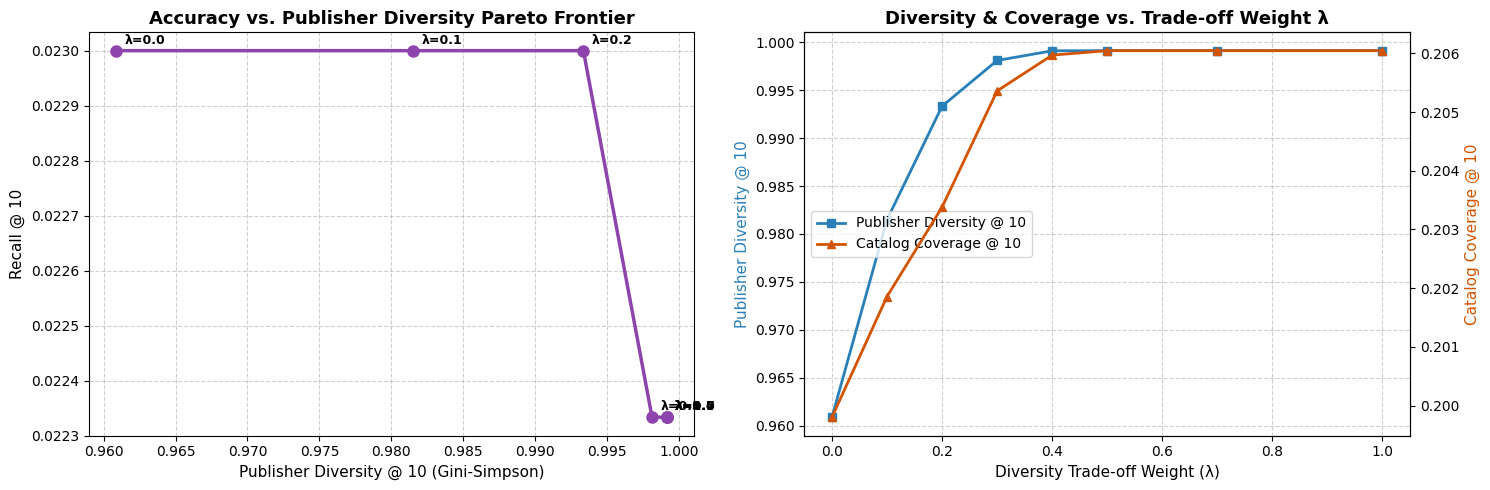

In [11]:
# 10. Accuracy vs. Diversity Sweep across Lambda in [0.0, 1.0]
sweep_lams = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0]
tradeoff_res = []
for lam in sweep_lams:
    res = evaluate_standalone(model, dataset, dataset.val_uv, topk=10, lam_div=lam, method='mmr')
    res['lambda'] = lam
    tradeoff_res.append(res)

import matplotlib.pyplot as plt
import pandas as pd

df_bench = pd.DataFrame(tradeoff_res)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Pareto frontier
p_divs = df_bench['Publisher_Diversity@10'].values
recs = df_bench['Recall@10'].values
axes[0].plot(p_divs, recs, 'o-', color='#8e44ad', linewidth=2.5, markersize=8)
for l, x, y in zip(df_bench['lambda'], p_divs, recs):
    axes[0].annotate(f'λ={l:.1f}', (x, y), textcoords='offset points', xytext=(6, 5), fontsize=9, fontweight='bold')
axes[0].set_xlabel('Publisher Diversity @ 10 (Gini-Simpson)', fontsize=11)
axes[0].set_ylabel('Recall @ 10', fontsize=11)
axes[0].set_title('Accuracy vs. Publisher Diversity Pareto Frontier', fontsize=13, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Progression curve
ax2 = axes[1]
ax2_r = ax2.twinx()
l1 = ax2.plot(df_bench['lambda'], p_divs, 's-', color='#2980b9', linewidth=2, label='Publisher Diversity @ 10')
l2 = ax2_r.plot(df_bench['lambda'], df_bench['Catalog_Coverage@10'], '^-', color='#d35400', linewidth=2, label='Catalog Coverage @ 10')
ax2.set_xlabel('Diversity Trade-off Weight (λ)', fontsize=11)
ax2.set_ylabel('Publisher Diversity @ 10', color='#2980b9', fontsize=11)
ax2_r.set_ylabel('Catalog Coverage @ 10', color='#d35400', fontsize=11)
ax2.set_title('Diversity & Coverage vs. Trade-off Weight λ', fontsize=13, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.6)
lines = l1 + l2
ax2.legend(lines, [l.get_label() for l in lines], loc='center left', fontsize=10)
plt.tight_layout()
plt.show()


  FEED RECOMMENDATION COMPARISON FOR USER 42
Rank  | Baseline (λ=0.0) [Creator]   | Diversified (λ=0.4) [Creator] 
----------------------------------------------------------------------
1     | Video  1848 (Creator  181)     | Video  1848 (Creator  181)
2     | Video   878 (Creator   29)     | Video   878 (Creator   29)
3     | Video  1380 (Creator  394)     | Video  1380 (Creator  394)
4     | Video  1385 (Creator    9)     | Video  1385 (Creator    9)
5     | Video  1267 (Creator   29)     | Video  1645 (Creator  111)
6     | Video  1645 (Creator  111)     | Video  3919 (Creator   18)
7     | Video  2594 (Creator  111)     | Video  1567 (Creator  258)
8     | Video  3919 (Creator   18)     | Video  1625 (Creator  217)
9     | Video   888 (Creator   18)     | Video    82 (Creator   64)
10    | Video  1567 (Creator  258)     | Video  3318 (Creator   14)



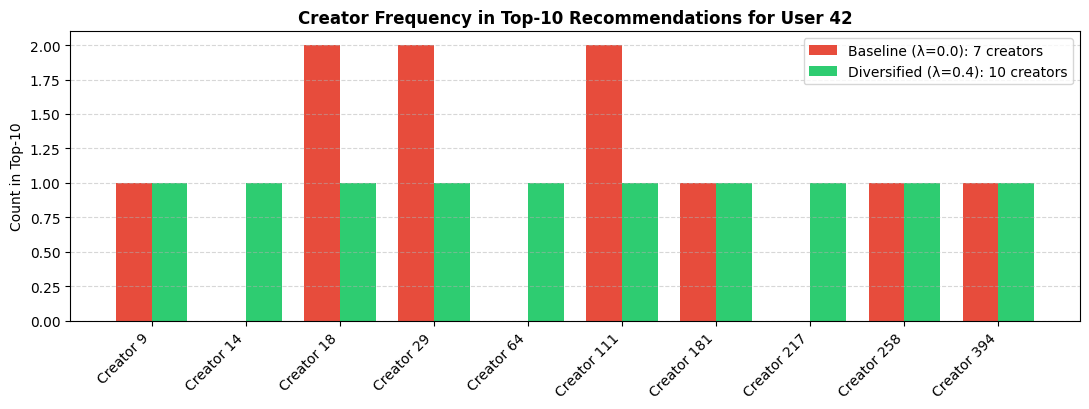

In [12]:
# 11. Interactive User Feed Demo & Creator Distribution Breakdown
DEMO_USER = 42
DIV_LAMBDA = 0.4
TOPK = 10

with torch.no_grad():
    u_v, v_v, u_a, a_a = model.forward(dataset.graph_uv, dataset.graph_ua)
    p_of_v = a_a[dataset.vlogger_list]
    w_g = model.compute_adaptive_gate(v_v, p_of_v)
    s_v = torch.matmul(u_v[DEMO_USER:DEMO_USER+1], v_v.T)
    s_a = torch.matmul(u_a[DEMO_USER:DEMO_USER+1], p_of_v.T)
    raw_scores = (s_v * w_g.unsqueeze(0) + s_a * (1.0 - w_g.unsqueeze(0))).squeeze(0).cpu().numpy()
    if len(dataset.train_uv[DEMO_USER]) > 0:
        raw_scores[dataset.train_uv[DEMO_USER]] = -1e9

    base_ids = np.argpartition(-raw_scores, TOPK)[:TOPK]
    base_ids = base_ids[np.argsort(-raw_scores[base_ids])].tolist()

    # MMR diversification
    cand_pool = np.argpartition(-raw_scores, 100)[:100]
    cand_pool = cand_pool[np.argsort(-raw_scores[cand_pool])]
    p_scores = raw_scores[cand_pool]
    n_scores = (p_scores - p_scores.min()) / (p_scores.max() - p_scores.min() + 1e-8)

    div_ids, div_vlogs = [], set()
    rem = list(range(len(cand_pool)))
    for _ in range(TOPK):
        bi, b_mmr = -1, -1e9
        for idx in rem:
            vl = dataset.vlogger_list[cand_pool[idx]]
            dist = 1.0 if (len(div_ids) == 0 or vl not in div_vlogs) else 0.0
            val = (1 - DIV_LAMBDA) * n_scores[idx] + DIV_LAMBDA * dist
            if val > b_mmr:
                b_mmr = val
                bi = idx
        sv = cand_pool[bi]
        div_ids.append(sv)
        div_vlogs.add(dataset.vlogger_list[sv])
        rem.remove(bi)

print(f'\n{"="*70}')
print(f'  FEED RECOMMENDATION COMPARISON FOR USER {DEMO_USER}')
print(f'{"="*70}')
print(f'{"Rank":<5} | {"Baseline (λ=0.0) [Creator]":<28} | {"Diversified (λ="+str(DIV_LAMBDA)+") [Creator]":<30}')
print(f'{"-"*70}')
for r in range(TOPK):
    bv = base_ids[r]
    dv = div_ids[r]
    print(f"{r+1:<5} | Video {bv:>5d} (Creator {dataset.vlogger_list[bv]:>4d})     | Video {dv:>5d} (Creator {dataset.vlogger_list[dv]:>4d})")
print(f'{"="*70}\n')

b_cnt = Counter([dataset.vlogger_list[v] for v in base_ids])
d_cnt = Counter([dataset.vlogger_list[v] for v in div_ids])
all_creators = sorted(list(set(list(b_cnt.keys()) + list(d_cnt.keys()))))
xp = np.arange(len(all_creators))
w = 0.38

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(xp - w/2, [b_cnt.get(c, 0) for c in all_creators], width=w, label=f'Baseline (λ=0.0): {len(b_cnt)} creators', color='#e74c3c')
ax.bar(xp + w/2, [d_cnt.get(c, 0) for c in all_creators], width=w, label=f'Diversified (λ={DIV_LAMBDA}): {len(d_cnt)} creators', color='#2ecc71')
ax.set_xticks(xp)
ax.set_xticklabels([f'Creator {c}' for c in all_creators], rotation=45, ha='right')
ax.set_ylabel('Count in Top-10')
ax.set_title(f'Creator Frequency in Top-{TOPK} Recommendations for User {DEMO_USER}', fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5, axis='y')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()